# Question 1: The Mechanics of Learning – Optimizers, Normalization, and Memory

**Estimated Time:** 7 Hours  
**Total:** 55 Points  
**Objective:** Understand how optimizers navigate the loss landscape, why normalization layers are critical, and how to train models on hardware-constrained settings.  
**Dataset:** CIFAR-10 (via `torchvision.datasets`).

## Part A: Theoretical Foundations [25 Points]

### 1A.1 Optimizer Dynamics [5 pts]
The standard SGD update is:

$$
w_{t+1} = w_t - \eta\,\nabla L(w_t)
$$

**(a)** Write the modified update equation when a momentum term $\beta$ is added. Explain how the velocity term helps escape shallow local minima and reduces oscillation in narrow ravines.  
**(b)** In one sentence, explain why Nesterov momentum is called **look-ahead** momentum.

## Answer
**(a)**
The modified equation when $\beta$ is added is:
$$v_{t+1} = \beta v_t + \nabla L(w_t)  $$
$$
w_{t+1} = w_t - \eta v_{t+1}$$

The velocity term has the previous velocity information, which helps the optimizer to maintain its direction and speed, espically when it is near shallow regions becuase of the previous velocity term, even if the gradient is small or zero the weight updates still occurs, allowing it to escape shallow local minima. The osciallation reduction is becuase of the direct and speed which comes from previous velocity, this makes convergence much faster.

**(b)** 
Nesterov accelerated gradient or momentum is formaulated like this: 

$$v_{t+1} = \beta v_t + \nabla L(w_t - \eta \beta v_t)  $$
$$
w_{t+1} = w_t - \eta v_{t+1}$$

This is called look-ahead momentum because the gradient is calculated at the "look-ahead" position $w_t - \eta \beta v_t$, which roughly estimate the future position of the parameters based on the current velocity, this results in better updates and faster convergence.

### 1A.2 Adaptive vs. Fixed Learning Rates [5 pts]

**(a)** Adam keeps first- and second-moment estimates of gradients. Explain intuitively why this gives a warm-start advantage over vanilla SGD in early epochs.  
**(b)** ImageNet practitioners often switch from Adam to SGD-with-momentum after an initial phase. Give one concrete reason related to the Adam vs SGD generalization gap.

### Answer 

**(a)** 

The adam updates are given by:
$$firstmoment_{t} = \beta_1 firstmoment_{t-1} + (1 - \beta_1) \nabla L(w_t)$$
$$secondmoment_{t} = \beta_2 secondmoment_{t-1} + (1 - \beta_2) (\nabla L(w_t))^2 $$
$${firstmoment}_{t} = \frac{firstmoment_{t}}{1 - \beta_1^t} $$
$${secondmoment}_{t} = \frac{secondmoment_{t}}{1 - \beta_2^t} $$
$$w_{t+1} = w_t - \eta \frac{{firstmoment}_{t}}{\sqrt{{secondmoment}_{t}} + \epsilon}$$

Adam's adaptive learning rates allow it to make larger updates for infrequent parameters and smaller updates for frequent parameters, which can lead to faster convergence in the early epochs when the model is still learning the basic structure of the data. This warm-start advantage helps Adam quickly find a good region in the loss landscape, while vanilla SGD may struggle with slow progress due to its fixed learning rate.


**(b)** 

Adam is quick at finding the good region in the loss landscape, this is very helpful in starting phase of training during initial epoches. later on, Adam would try to reach to the absolute minima for training data, which may lead to ovefitting and poor genralization. that's why later on imagenet practitioners shift to sgd with momemtum or NAG, which can give much better generalization for the model.


**reference**: https://arxiv.org/pdf/1609.04747 for first 2 questions 

### 1A.3 Why Batch Normalization? [8 pts]

**(a) Internal Covariate Shift (3 pts).** In a 10-layer MLP where each layer doubles pre-activation magnitude, by what factor does magnitude grow after 10 layers? Why does this make learning-rate selection difficult?

**(b) Mechanics of BatchNorm (3 pts).** For mini-batch $\{x_1,\ldots,x_B\}$:

$$
\hat{x}_i = \frac{x_i - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}},\qquad
y_i = \gamma\hat{x}_i + \beta
$$

Explain roles of $\gamma$, $\beta$, and why pure normalization alone is insufficient.

**(c) BatchNorm at Test Time (2 pts).** Since $\mu_B,\sigma_B^2$ are unavailable at inference, explain which running statistics are used and how they are computed during training.

### 1A.4 Gradient Accumulation [4 pts]
Your GPU supports $B_{small}=8$, but you want effective batch $B_{large}=32$.

**(a)** Show mathematically that accumulating gradients over $N=4$ micro-batches (8 each), then calling `optimizer.step()` once, matches the update of a true batch of 32.  
**(b)** Does gradient accumulation produce exactly the same BatchNorm statistics as a true batch of 32? Why or why not?

### 1A.5 Quick Conceptual Questions [3 pts, 1 pt each]
Answer each in at most two sentences.

**(a)** Why is convolutional bias redundant when immediately followed by BatchNorm?  
**(b)** If BatchNorm \(\gamma,\beta\) are frozen, does training still benefit from normalization? Briefly justify.  
**(c)** AdamW applies weight decay directly to weights, not gradients. Why is this called decoupled weight decay?

### Hint
For Q1A.3(a), think in powers of 2. For Q1A.4(b), think about which micro-batch BatchNorm running stats are computed from.

## Part B: Practical Implementation [30 Points]

### 1B.1 Optimizer Face-off [10 pts]
Train the same CNN architecture for 15 epochs using:
- Vanilla SGD ($\eta=0.01$)
- SGD + momentum ($\eta=0.01,\ \beta=0.9$)
- AdamW ($\eta=0.001$, default betas)

Plot training loss and validation accuracy curves in one figure (two subplots), and write a 3–4 sentence interpretation.

In [ ]:
# downloading cifar-10 dataset 
import torch
from torchvision import datasets
import torchvision.transforms as transforms
from torch import nn
from torch.utils.data import DataLoader

torch.manual_seed(42)
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
print(device)

train_data = datasets.CIFAR10(root='data', train=True, download=True, transform=transforms.ToTensor(),)
data_loader = DataLoader(train_data, batch_size=8, shuffle=True, pin_memory=True)
test_data = datasets.CIFAR10(root='data', train=False, download=True, transform=transforms.ToTensor())
test_loader = DataLoader(test_data, batch_size=8, shuffle=False, pin_memory=True)

cuda


/home/vanshnawander/miniconda3/envs/fi-bench/lib/python3.12/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


In [9]:
train_data

Dataset CIFAR10
    Number of datapoints: 50000
    Root location: data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [ ]:
class ShallowCNN(nn.Module):
    def __init__(self):
        super(ShallowCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 5, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.conv2 = nn.Conv2d(5, 3, kernel_size=3, stride=1, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.fc1 = nn.Linear(3 * 8 * 8, 10)


    def forward(self, x):
        x = self.conv1(x)
        x = self.pool(torch.relu(x))
        x = self.conv2(x)
        x = self.pool(torch.relu(x))
        x = x.view(-1, 3 * 8 * 8)
        x = self.fc1(x)
        return x

In [16]:
model_vanilla_sgd = ShallowCNN()
model_sgd_momentum = ShallowCNN()
model_adam = ShallowCNN()
print(model_vanilla_sgd, model_sgd_momentum, model_adam)

ShallowCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=10, bias=True)
) ShallowCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=10, bias=True)
) ShallowCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, k

In [12]:
model_vanilla_sgd.to(device)
model_sgd_momentum.to(device)
model_adam.to(device)

ShallowCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=10, bias=True)
)

In [13]:
def evaluate(model, data_loader, device):
    model.eval()  # switch to eval mode for testing data
    correct = 0
    total = 0

    with torch.no_grad(): 
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            x, preds = torch.max(outputs, 1)

            correct += (preds == labels).sum().item()
            total += labels.size(0)

    model.train()  # switch back to train mode
    return 100 * correct / total

In [14]:
loss_fn = nn.CrossEntropyLoss()
optimizer_vanilla_sgd = torch.optim.SGD(model_vanilla_sgd.parameters(), lr=0.01)
optimizer_sgd_momentum = torch.optim.SGD(model_sgd_momentum.parameters(), lr=0.01, momentum=0.9)
optimizer_adam = torch.optim.Adam(model_adam.parameters(), lr=0.001)

vanila_loss = []
momentum_loss = []
adam_loss = []

vanila_acc = [] 
momentum_acc = []
adam_acc = []

for epoch in range(15):
    for images, labels in data_loader:
        images, labels = images.to(device), labels.to(device)


        pred_vanilla_sgd = model_vanilla_sgd(images)
        loss1 = loss_fn(pred_vanilla_sgd, labels)
        optimizer_vanilla_sgd.zero_grad()
        loss1.backward()
        optimizer_vanilla_sgd.step()

        pred_sgd_momentum = model_sgd_momentum(images)
        loss2 = loss_fn(pred_sgd_momentum, labels)
        optimizer_sgd_momentum.zero_grad()
        loss2.backward()
        optimizer_sgd_momentum.step()


        pred_adam = model_adam(images)
        loss3 = loss_fn(pred_adam, labels)
        optimizer_adam.zero_grad()
        loss3.backward()
        optimizer_adam.step()

    acc_sgd = evaluate(model_vanilla_sgd, test_loader, device)
    acc_momentum = evaluate(model_sgd_momentum, test_loader, device)
    acc_adam = evaluate(model_adam, test_loader, device)



    vanila_loss.append(loss1.item())
    momentum_loss.append(loss2.item())
    adam_loss.append(loss3.item())

    vanila_acc.append(acc_sgd)
    momentum_acc.append(acc_momentum)
    adam_acc.append(acc_adam)

    print(f'Epoch [{epoch+1}/15], Loss: sgd loss {loss1.item():.4f} \n, sgd momentum loss {loss2.item():.4f} \n, Adam loss {loss3.item():.4f}')
    print('testloss')
    print(f'Vanilla SGD Accuracy: {acc_sgd:.2f}%')
    print(f'SGD with Momentum Accuracy: {acc_momentum:.2f}%')
    print(f'Adam Accuracy: {acc_adam:.2f}%')

Epoch [1/15], Loss: 2.0805 , 1.4472 , 1.5925
testloss
Vanilla SGD Accuracy: 50.75%
SGD with Momentum Accuracy: 50.38%
Adam Accuracy: 57.60%
Epoch [2/15], Loss: 0.9709 , 0.9913 , 0.9436
testloss
Vanilla SGD Accuracy: 58.73%
SGD with Momentum Accuracy: 52.72%
Adam Accuracy: 61.55%
Epoch [3/15], Loss: 0.9033 , 1.4269 , 0.8279
testloss
Vanilla SGD Accuracy: 60.82%
SGD with Momentum Accuracy: 51.59%
Adam Accuracy: 62.13%
Epoch [4/15], Loss: 0.9073 , 0.9953 , 0.7179
testloss
Vanilla SGD Accuracy: 64.10%
SGD with Momentum Accuracy: 53.59%
Adam Accuracy: 63.32%
Epoch [5/15], Loss: 1.2525 , 1.0207 , 1.3718
testloss
Vanilla SGD Accuracy: 65.17%
SGD with Momentum Accuracy: 53.34%
Adam Accuracy: 65.52%
Epoch [6/15], Loss: 1.3095 , 1.4777 , 1.0511
testloss
Vanilla SGD Accuracy: 65.56%
SGD with Momentum Accuracy: 52.58%
Adam Accuracy: 64.74%
Epoch [7/15], Loss: 0.9988 , 1.8919 , 1.5879
testloss
Vanilla SGD Accuracy: 65.33%
SGD with Momentum Accuracy: 53.07%
Adam Accuracy: 65.87%
Epoch [8/15], Loss: 

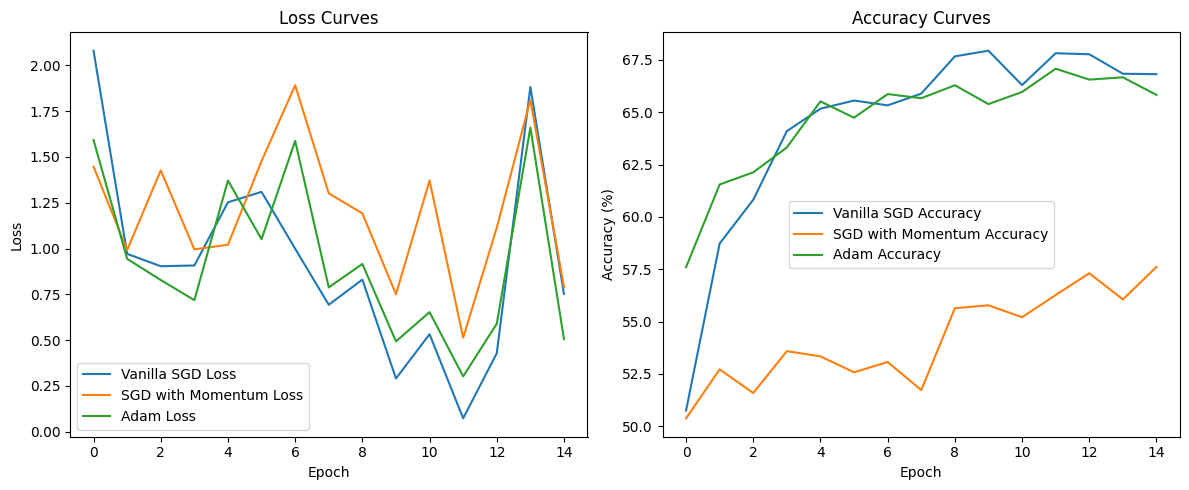

In [15]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(vanila_loss, label='Vanilla SGD Loss')
plt.plot(momentum_loss, label='SGD with Momentum Loss')
plt.plot(adam_loss, label='Adam Loss')
plt.title('Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(vanila_acc, label='Vanilla SGD Accuracy')
plt.plot(momentum_acc, label='SGD with Momentum Accuracy')
plt.plot(adam_acc, label='Adam Accuracy')
plt.title('Accuracy Curves')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.tight_layout()
plt.show()

### 1B.2 BatchNorm Ablation [8 pts]
Using best optimizer from 1B.1, train two CNN variants:
- With BatchNorm after every Conv2D (before ReLU)
- Without normalization

Plot both training loss curves together, report final validation accuracy for both, and explain the gap in 2–3 sentences.

In [ ]:

class ShallowCNNwithBatchNorm(nn.Module):
    def __init__(self):
        super(ShallowCNNwithBatchNorm, self).__init__()
        self.conv1 = nn.Conv2d(3, 5, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.conv2 = nn.Conv2d(5, 3, kernel_size=3, stride=1, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.fc1 = nn.Linear(3 * 8 * 8, 10)


    def forward(self, x):
        x = self.conv1(x)
        x = nn.BatchNorm2d(5)(x)
        x = self.pool(torch.relu(x))
        x = self.conv2(x)
        x = nn.BatchNorm2d(3)(x)
        x = self.pool(torch.relu(x))
        x = x.view(-1, 3 * 8 * 8)
        x = self.fc1(x)
        return x

### 1B.3 Focal Loss [6 pts]
Implement Focal Loss:

$$
FL(p_t) = -\alpha_t(1-p_t)^\gamma\log(p_t),\quad \gamma=2.0
$$

Train BatchNorm-equipped CNN with Focal Loss and compare validation accuracy against Cross-Entropy. Briefly explain when Focal Loss is advantageous.

In [ ]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=1, gamma=2):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        focal_loss =  - self.alpha * ((1 - inputs) ** self.gamma )* torch.log(inputs)
        return focal_loss

### 1B.4 Gradient Accumulation in PyTorch [6 pts]
Set DataLoader `batch_size=8`. Accumulate gradients over 4 micro-batches before `optimizer.step()` (effective batch = 32).
Print loss for first 50 optimizer steps and verify it decreases.

In [ ]:
NUM_ACCUMULATION_STEPS = 4

for epoch in range(15):
    for images, labels in data_loader:
        images, labels = images.to(device), labels.to(device)


        pred_vanilla_sgd = model_vanilla_sgd(images)
        loss= loss_fn(pred_vanilla_sgd, labels)
        loss = loss / NUM_ACCUMULATION_STEPS
        loss.backward()

        if (epoch + 1) % NUM_ACCUMULATION_STEPS == 0:
            optimizer_vanilla_sgd.zero_grad()
            optimizer_vanilla_sgd.step()



## AI Attribution
- It helped me a lot in formatting this to a proper format espically the markdown cells latex part.